# Multimodal example, step by step

The analysis of [`multimodal.workflow.yaml`](multimodal.workflow.yaml), run one
step at a time in a notebook instead of with `m3resp run`.

Every call lists all the settings the function takes. Settings the workflow file
sets have its values; the others are at their defaults.

## 1. Import the required libraries

In [1]:
from pathlib import Path

from m3resp import M3Session
from m3resp.visualization import plot_synchronization_comparison
from m3resp.workflows.steps import eit, emg, sync, ventilator

## 2. Load the EIT, EMG and ventilator data

In [2]:
data_dir = Path("../../tests/data")

session = M3Session()
eit_data = eit.load(
    session,
    file_path=data_dir / "m3resp_multimodal_1_eit_draeger.bin",
    vendor="draeger",  # "draeger", "sentec" or "timpel"
    sample_frequency=None,  # None: from the file (Draeger)
    first_frame=0,
    max_frames=None,  # None: read to the end
    loader_options=None,  # extra settings for the vendor loader
)
emg.load(
    session,
    file_path=data_dir / "m3resp_multimodal_1_emg.Poly5",
    loader_options=None,  # extra settings for M3Session.load_emg
)
vent_data = ventilator.load(
    session,
    file_path=data_dir / "m3resp_multimodal_1_ventilator.Poly5",
    source=None,  # which device's file this is; decides its clock
    name=None,  # name for this recording, when loading several
)

Reading file  ..\..\tests\data\m3resp_multimodal_1_emg.Poly5
	 Number of samples:  122880 
	 Number of channels:  2 
	 Sample rate: 2048 Hz
Done reading data.
Reading file  ..\..\tests\data\m3resp_multimodal_1_ventilator.Poly5
	 Number of samples:  6000 
	 Number of channels:  3 
	 Sample rate: 100 Hz
Done reading data.


In [3]:
# Put the recordings on one clock: the EMG recording started 2 s earlier
sync.raw_modalities(
    session,
    method="manual_offset",  # the only method
    offset_seconds={"eit": 0.0, "emg": -2.0, "vent": 0.0},
    reference_modality="vent",
)
session.start_times

{'eit': 0.0, 'emg': -2.0, 'ventilator': 0.0}

## 3. Process the EIT data

In [4]:
# Respiratory and heart rate
rates = eit.detect_rates(
    eit_data["raw_eit"],
    session=session,
    subject_type="adult",  # "adult" or "neonate"
    welch_window_seconds=30.0,  # None: the detector's default of 30 s
    capture=True,  # keep intermediate results for the figures
)
rates["respiratory_rate_hz"] * 60, rates["heart_rate_hz"] * 60  # per minute

(13.883484475314617, 95.75131922960281)

In [5]:
# Remove the cardiac component, then sum all pixels
filtered = eit.mdn_filter(
    eit_data["raw_eit"],
    respiratory_rate_hz=rates["respiratory_rate_hz"],
    heart_rate_hz=rates["heart_rate_hz"],
    eit_sequence=eit_data["eit_sequence"],
    session=session,
    label="mdn_filtered",
)
global_impedance = eit.global_impedance(
    filtered["filtered_eit"],
    eit_sequence=eit_data["eit_sequence"],
)["global_impedance"]

In [6]:
# Find the breaths and store them in the session
eit_breaths = eit.detect_breaths(
    global_impedance,
    min_duration_s=0.6666666667,
)
eit.normalize_breaths(
    eit_breaths["breath_intervals"],
    session=session,
)
len(session.events["eit_breaths"])

13

In [7]:
# Tidal impedance variation, end-expiratory lung impedance and pixel TIV per breath
tiv = eit.continuous_tiv(
    global_impedance,
    eit_sequence=eit_data["eit_sequence"],
    breath_detector=eit_breaths["breath_detector"],
    session=session,
)
eeli = eit.eeli(
    global_impedance,
    eit_sequence=eit_data["eit_sequence"],
    breath_detector=eit_breaths["breath_detector"],
    session=session,
    result_label="continuous_eelis",
)
pixel_tiv = eit.pixel_tiv(
    eit_data=filtered["filtered_eit"],
    signal=global_impedance,
    eit_sequence=eit_data["eit_sequence"],
    breath_detector=eit_breaths["breath_detector"],
    session=session,
    tiv_timing="continuous",  # "continuous" (from signal) or "pixel"
    result_label="pixel_tivs",
)

## 4. Process the EMG data

Channel 1 is the diaphragm EMG. The ECG is mixed into it, so the ECG peaks are
found in that channel too.

In [8]:
# Filter
emg_filtered = emg.preprocess(
    session,
    channel=1,  # None: chosen from the channel labels
    high_pass_hz=80,
    low_pass_hz=None,  # None: 500 Hz, or 95 % of Nyquist if lower
    notch_base_frequency=None,  # e.g. 50 for mains hum; None: no notch filter
    notch_max_frequency=None,  # None: Nyquist
    notch_quality_factor=30.0,
    notch_before_bandpass=False,
    variant=None,  # store under a named variant instead of the default
)["processed_emg"]

In [9]:
# ECG removal: find the ECG peaks, then gate them out
ecg = emg.ecg_detect_peaks(
    session,
    emg_filtered,
    ecg_channel=None,  # raw channel with the ECG; overrides source
    source="raw_channel",  # key of emg_filtered to detect the ECG in
    peak_fraction=0.4,
    peak_width_seconds=None,  # None: the detector's choice
    peak_distance_seconds=0.33,
    bandpass_filter=True,
)
emg_gated = emg.ecg_gating(
    session,
    emg_filtered,
    ecg["ecg_peak_indices"],
    source=None,  # None: the ECG-cleaned trace if present, else filtered
    gate_width_seconds=None,  # set this or gate_width_samples, not both
    gate_width_samples=None,  # None: 205 samples
    fill_method=1,  # 0 zeros, 1 interpolation, 2 neighbour mean, 3 running RMS
)["processed_emg_after_ecg"]
len(ecg["ecg_peak_indices"])

28

In [10]:
# Envelope and baseline
emg_processed = emg.envelope(
    session,
    emg_gated,
    window_seconds=0.25,
    method="rms",  # "rms", "arv" or "median"
    source=None,  # None: the ECG-cleaned trace if present, else filtered
)["processed_emg_with_envelope"]
emg_baseline = emg.slopesum_baseline(
    session,
    emg_processed,
    window_seconds=7.5,
    step_seconds=0.2,
    percentile=33.0,
    augmented_percentile=25.0,
    moving_average_seconds=0.5,
    percentile_window_seconds=1.0,
)["baseline"]

In [11]:
# Find the EMG breaths
emg_breaths = emg.detect_breaths(
    session,
    baseline=emg_baseline,
    variant=None,  # detect in a named preprocessing variant
    min_breath_width_seconds=1.0,
    distance_seconds=0.5,  # minimum time between breath peaks
    threshold=0,
    prominence_factor=0.5,
)["emg_breath_events"]
emg_peak_indices = emg.peak_indices(emg_breaths, emg_processed)["peak_indices"]
len(emg_breaths)

13

## 5. Process the ventilator data

In [12]:
vent_signals = ventilator.channels(
    vent_data["ventilator_raw"],
    channels=("airway_pressure", "flow", "volume"),
    airway_pressure_channel=0,  # None: found by channel label
    flow_channel=1,
    volume_channel=2,
    fs=None,  # None: from the recording
)["ventilator_signals"]

In [13]:
# Occlusion manoeuvres (Pocc): find them, their start and end, their
# pressure-time product and their quality
pocc_indices = ventilator.find_occluded_breaths(
    vent_signals,
    peep=None,  # None: estimated from the end-expiratory pressure
)["pocc_indices"]
pocc = ventilator.pocc_intervals(
    session,
    vent_signals,
    pocc_indices,
    baseline_window_seconds=7.5,
    baseline_step_seconds=0.2,
    baseline_percentile=33.0,
)
pocc_time_products = ventilator.pocc_time_product(
    session,
    vent_signals,
    pocc["pocc_start_indices"],
    pocc["pocc_end_indices"],
    pocc["pressure_baseline"],
    pocc_indices=pocc_indices,
    include_aub=True,  # add the area under the baseline
    aub_window_seconds=5.0,
)["pocc_time_products"]
pocc_quality = ventilator.pocc_quality(
    session,
    vent_signals,
    pocc_indices,
    pocc["pocc_end_indices"],
    pocc_time_products,
    dp_up_10_threshold=0.0,
    dp_up_90_threshold=2.0,
    dp_up_90_norm_threshold=0.8,
)["pocc_quality"]
pocc_time_products, pocc_quality

(array([3.91020645, 5.2099872 ]), array([ True,  True]))

In [14]:
# Ventilator breaths
vent_breath_indices = ventilator.detect_breaths(
    vent_signals,
    breath_width_seconds=0.5,
)["ventilator_breath_indices"]
ventilator.detect_non_consecutive_manoeuvres(
    session,
    vent_breath_indices,
    pocc_indices,
)
ventilator.normalize_breaths(
    vent_breath_indices,
    vent_signals,
    session,
    breath_width_seconds=0.5,
)
len(session.events["ventilator_breaths"])

13

## 6. Results

In [15]:
{name: len(events) for name, events in session.events.items()}

{'eit_breaths': 13,
 'ecg_peaks': 28,
 'emg_breaths': 13,
 'pocc_breaths': 2,
 'ventilator_breaths': 13}

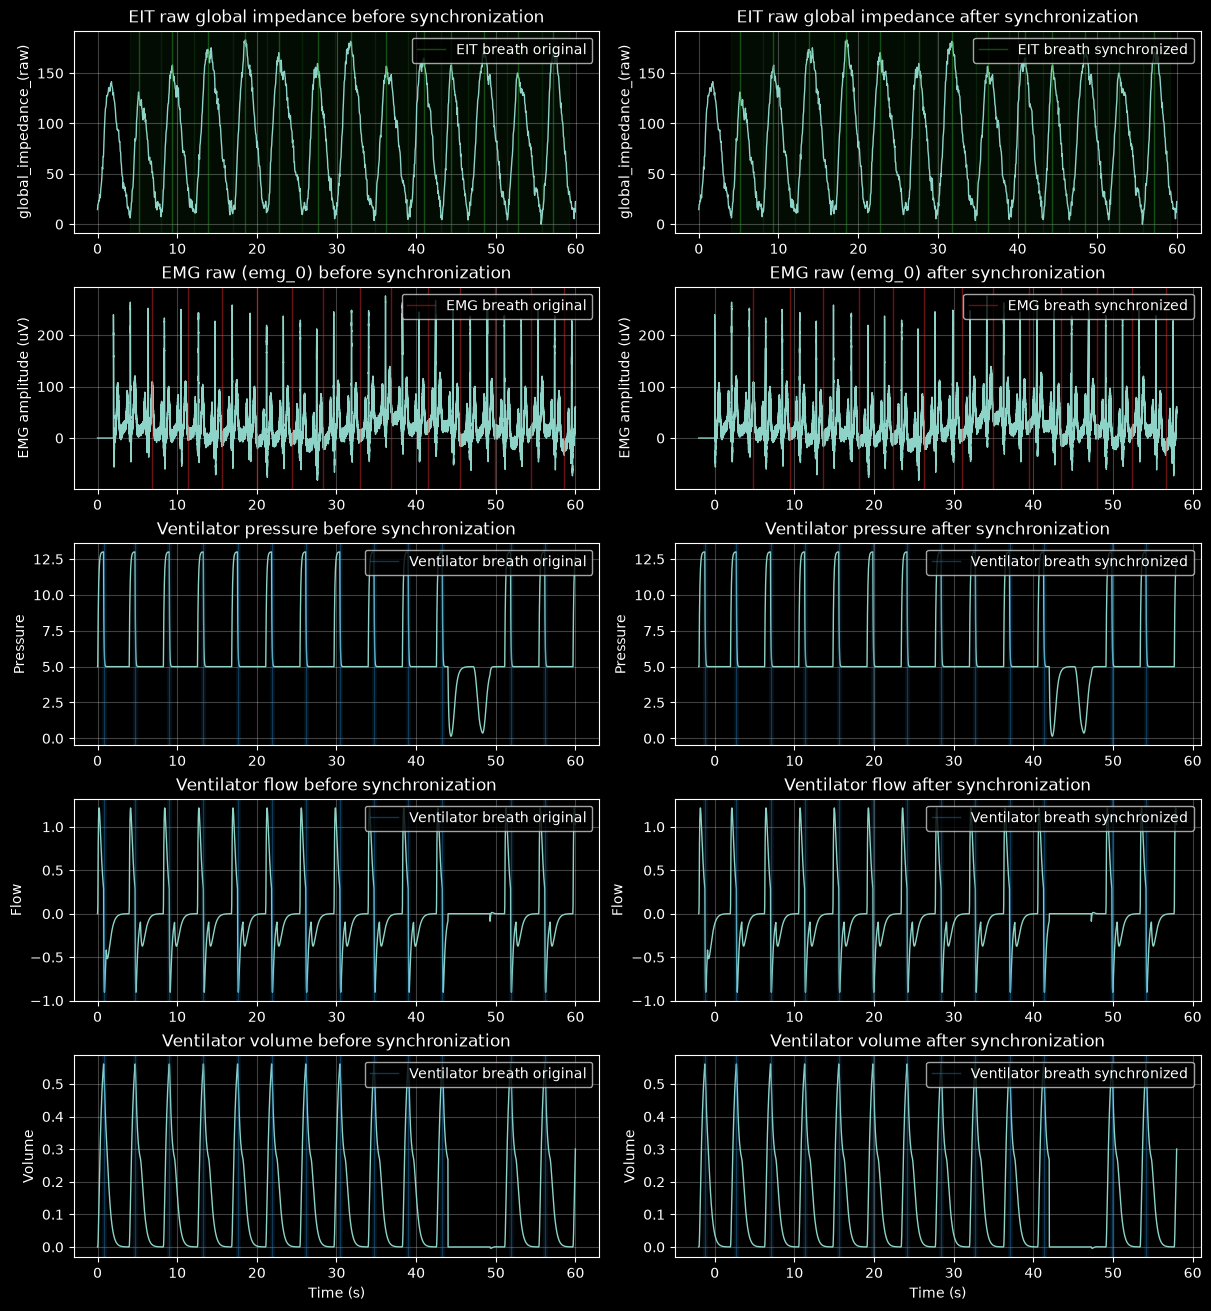

In [16]:
# Each signal with its breaths, before and after synchronization
fig = plot_synchronization_comparison(
    session,
    max_seconds=120.0,  # None: the whole recording
    emg_channel=1,  # the channel the EMG processing used
    eit_waveform="global_impedance_(raw)",
    backend="matplotlib",  # or "plotly"
    max_points=5000,
)